# Failure Classification for Predictive Maintenance

The anomaly detector asked whether a machine record looked unusual relative to normal behavior. This notebook asks a different question:

> Can we predict whether a machine record is a failure or no-failure case?

This is supervised classification because the `Machine failure` label is used during training. The current decision tree catches **63 of 68 test failures**, but it also raises **143 false alarms**. The purpose of this notebook is therefore not only to measure accuracy, but to study the tradeoff between detecting failures and creating unnecessary maintenance alerts.


## Step 1: Importing Libraries and Loading the Dataset

The notebook loads **10,000 records and 14 columns**. It uses the same six leakage-safe inputs as the previous notebooks, but now `Machine failure` is explicitly used as the target that the model learns to predict.


In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

df = pd.read_csv('../../data/raw/ai4i2020.csv')
df.head()

,UID,Product ID,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## Step 2: Define Features and Target

`X` contains the six variables the model is allowed to see: machine `Type`, air temperature, process temperature, rotational speed, torque, and tool wear. Its shape is **(10,000, 6)**.

`y` contains the binary `Machine failure` target and has shape **(10,000,)**. The observed failure rate is **3.39%**.

`TWF`, `HDF`, `PWF`, `OSF`, and `RNF` are not input features because they are failure-mode labels derived from failure conditions. Including them would leak information about the target and produce unrealistically optimistic performance.


In [15]:
input_features = [
    'Type',
    'Air temperature',
    'Process temperature',
    'Rotational speed',
    'Torque',
    'Tool wear',
]

numeric_features = [
    'Air temperature',
    'Process temperature',
    'Rotational speed',
    'Torque',
    'Tool wear',
]

categorical_features = ['Type']

X = df[input_features].copy()
y = df['Machine failure'].copy()

print('X shape:', X.shape)
print('y shape:', y.shape)
print('Failure rate:', f'{y.mean():.2%}')

X shape: (10000, 6)
y shape: (10000,)
Failure rate: 3.39%


## Step 3: Train/Test Split

A stratified 80/20 split creates **8,000 training records** and **2,000 test records**. The training set contains 7,729 no-failure records and 271 failures, while the test set contains 1,932 no-failure records and 68 failures. The failure rates remain approximately 3.39% and 3.40%, making the test set representative of the original imbalance.


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Training records:', len(X_train))
print('Test records:', len(X_test))
print('Training failure rate:', f'{y_train.mean():.2%}')
print('Test failure rate:', f'{y_test.mean():.2%}')

Training records: 8000
Test records: 2000
Training failure rate: 3.39%
Test failure rate: 3.40%


## Step 4: Build a Preprocessing + Classification Pipeline

A pipeline keeps preprocessing and modeling together and ensures that transformations are learned from training data during `fit()` and reused consistently during prediction.

The preprocessing step:

- standardizes the five numerical sensor features;
- one-hot encodes `Type`, while safely ignoring unseen categories.

The classifier is a decision tree with `max_depth=4`. The depth limit restricts complexity and keeps the learned rules interpretable. The fitted tree reaches depth 4 and contains 16 leaves.

`class_weight='balanced'` gives the rare failure class substantially more influence during training. In this split, a failure record receives about 28.5 times the weight of a no-failure record. This encourages high failure recall but can increase false alarms. Although scaling is not required by a decision tree, it keeps preprocessing consistent with the other project stages.


In [6]:
preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', StandardScaler(), numeric_features),
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
    ]
)

classifier = DecisionTreeClassifier(
    max_depth=4,
    class_weight='balanced',
    random_state=42
)

model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', classifier),
    ]
)

model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, 

## Step 5: Train the Classifier

Training means the tree searches for feature thresholds that separate failure from no-failure records while accounting for the balanced class weights.

Unlike anomaly detection, this model sees both:

- input features `X_train`
- target labels `y_train`

So this is supervised learning. The test set is not used to choose the splits; it remains unseen until evaluation.


In [17]:
model.fit(X_train, y_train)

print('Model training complete.')

Model training complete.


## Step 6: Make Predictions

The model predicts **1,794 test records as no failure** and **206 as failure**. Because only 68 test records actually failed, the predicted failure rate (10.30%) is much larger than the actual failure rate (3.40%). This is an early indication that the class weighting favors sensitivity and produces false alarms.


In [18]:
y_pred = model.predict(X_test)

prediction_counts = pd.Series(y_pred).value_counts().sort_index()
prediction_counts

0    1794
1     206
Name: count, dtype: int64

## Step 7: Evaluate the Classifier

Because failures are rare, accuracy alone is not enough. The confusion matrix from the current run is:

| Actual condition | Predicted no failure | Predicted failure |
|---|---:|---:|
| No failure | 1,789 (TN) | 143 (FP) |
| Failure | 5 (FN) | 63 (TP) |


Important metrics:

- **Accuracy = 0.9260:** 92.60% of all test predictions are correct.
- **Precision = 0.3058:** 30.58% of failure alerts correspond to actual failures.
- **Recall = 0.9265:** 92.65% of actual failures are detected.
- **F1-score = 0.4599:** harmonic balance between precision and recall.

The 92.60% accuracy is lower than the 96.61% accuracy of a naive always-no-failure rule, but the naive rule would detect zero failures. The model misses only five failures, while the 143 false positives mean that most failure alerts are false alarms. In predictive maintenance, this may be acceptable when missed failures are much more costly than inspections, but the tradeoff must be documented rather than hidden behind accuracy.


In [20]:
metrics = {
    'accuracy': accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred, zero_division=0),
    'recall': recall_score(y_test, y_pred, zero_division=0),
    'f1': f1_score(y_test, y_pred, zero_division=0),
}

pd.DataFrame([metrics]).round(4)

,accuracy,precision,recall,f1
0,0.926,0.3058,0.9265,0.4599


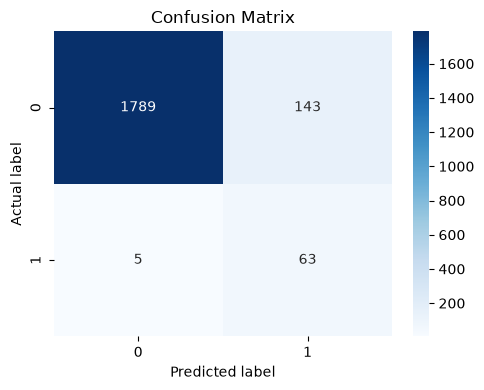

              precision    recall  f1-score   support

  No failure       1.00      0.93      0.96      1932
     Failure       0.31      0.93      0.46        68

    accuracy                           0.93      2000
   macro avg       0.65      0.93      0.71      2000
weighted avg       0.97      0.93      0.94      2000



In [21]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted label')
plt.ylabel('Actual label')
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, target_names=['No failure', 'Failure'], zero_division=0))

## Step 8: Explain the Classifier Globally

Global explanation asks:

> Which features were most important overall?

The fitted tree assigns importance as follows:

| Feature | Importance |
|---|---:|
| Rotational speed | 0.3543 |
| Torque | 0.3460 |
| Tool wear | 0.2673 |
| Air temperature | 0.0294 |
| Process temperature | 0.0032 |
| Type indicators | 0.0000 |

Rotational speed, torque, and tool wear account for nearly all tree importance, agreeing with the earlier exploratory and anomaly findings. Tree importance measures how much a feature reduces split impurity; it does not show whether a high value increases risk, explain individual predictions, or prove physical causation. SHAP and LIME are introduced later to address local prediction explanations.


In [13]:
feature_names = model.named_steps['preprocessor'].get_feature_names_out()
importances = model.named_steps['classifier'].feature_importances_

feature_importance = pd.DataFrame({
    'feature': feature_names,
    'importance': importances,
}).sort_values('importance', ascending=False)

feature_importance

,feature,importance
2,numeric__Rotational speed,0.354252
3,numeric__Torque,0.345959
4,numeric__Tool wear,0.267254
0,numeric__Air temperature,0.029370
1,numeric__Process temperature,0.003165
5,categorical__Type_H,0.000000
6,categorical__Type_L,0.000000
7,categorical__Type_M,0.000000


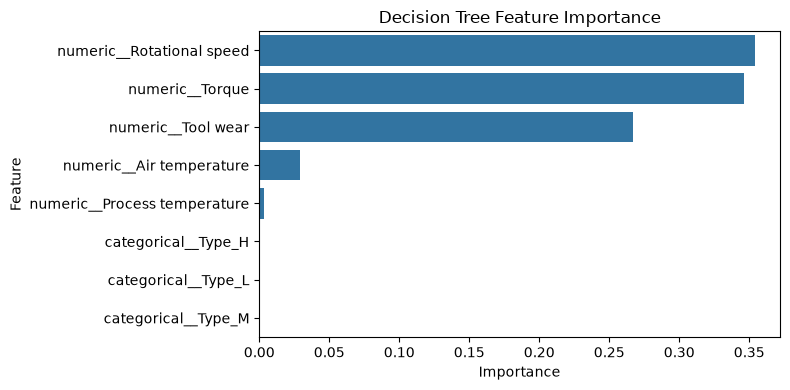

In [12]:
plt.figure(figsize=(8, 4))
sns.barplot(data=feature_importance, x='importance', y='feature')
plt.title('Decision Tree Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## Step 9: Compare Classification With Anomaly Detection

The two models provide different signals and were trained for different objectives:

- anomaly detection identifies unusual behavior relative to normal records;
- classification identifies patterns associated with labelled failures.

| Method | Records flagged | Failures flagged | No-failure records flagged | Failure overlap recall | Flag precision |
|---|---:|---:|---:|---:|---:|
| Isolation Forest (Anomaly Detection) | 113 | 16 | 97 | 23.53% | 14.16% |
| Decision tree classifier | 206 | 63 | 143 | 92.65% | 30.58% |

The classifier catches 47 more known failures because it learns directly from failure labels. It also creates more alerts. Isolation Forest remains useful for discovering unusual behavior that may not match previously labelled failure patterns, so the methods are complementary rather than interchangeable.

Overall, the depth-4 balanced decision tree provides high failure recall but low alert precision. The next research steps are threshold and class-weight analysis, error analysis of the five missed failures and 143 false alarms, and local explanations showing why individual records receive their predictions.
